# 05 · Q&A: Configuration Selection (rubric 3) & Evaluation (rubric 4)

**Problem.** A user asked about Adani Enterprises' FY2024-25 revenue. The chat answered
**₹7,00,297.50 crore**, a number that appears nowhere in the report. The true consolidated total income
is ₹1,00,365.08 crore (statement of P&L, page 392). Retrieval had returned the Chairman's letter and an
ESG page instead of the P&L, and the 3B model filled the gap by inventing a number.

**Hypothesis.** Giving the model the **verified KPI table** (built and cleaned in notebooks 01–04) as an
extra, citable source will raise numeric accuracy and cut fabricated figures, even when retrieval misses
the statement page.

**Design.**
* **Gold set:** 26 answerable questions plus 4 unanswerable ones over all 6 reports
  (`ml/eval/rag_gold.json`). Every gold answer was read from a **financial-statement page**, never from
  the KPI table, which is one of the systems under test.
* **Three configurations.** The LLM (qwen2.5:3b), prompt, hardware and questions are identical; only the
  evidence changes.

| Config | Retrieval | Extra evidence |
|---|---|---|
| **A · dense** | bge-small cosine search only | none |
| **B · hybrid** | BM25 + bge → RRF → cross-encoder rerank | none |
| **C · hybrid + KPI facts** | as B | KPI table, *verified* rows only (+ prior year) |
| **D · hybrid + all cleaned KPIs** | as B | every KPI that survived cleansing, unchecked rows marked, plus an "exact row name" instruction |

D was added after the error analysis of C (§5): correct Total Assets rows were withheld from C because the
extractor never cross-checks that KPI.

* **Metrics** (`ml/eval/rag_scoring.py`):
  - **numeric accuracy:** the gold value is stated, ±0.5%;
  - **unit accuracy:** that figure also carries a correct unit;
  - **fabrication rate:** the answer states a figure found in none of its sources;
  - **citation rate**;
  - **refusal accuracy** on unanswerable questions;
  - **latency.**
* **Statistics:** 95% bootstrap confidence intervals, and **McNemar's test** for the paired difference
  between configurations, since they answer the same questions.

Runs are produced by `python -m ml.eval.run_rag_eval` and cached in `ml/data/rag_eval_runs.jsonl`.

In [1]:
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import binomtest

from ml.paths import DATA_DIR, FIGURES_DIR, ML_DIR, REPORTS_DIR
from ml.eval.rag_scoring import is_refusal, score_numeric, unsupported_figures
from ml.eval.run_rag_eval import CONFIGS

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 180)
LABEL = {"A_dense": "A · dense", "B_hybrid": "B · hybrid", "C_hybrid_facts": "C · hybrid + KPI facts",
         "D_hybrid_all_kpis": "D · hybrid + all cleaned KPIs"}


def save(name):
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"05_{name}.png", dpi=130)
    plt.show()

In [2]:
gold = json.loads((ML_DIR / "eval" / "rag_gold.json").read_text(encoding="utf-8"))
qs = pd.DataFrame(gold["questions"]).set_index("id")
runs = pd.DataFrame([json.loads(l) for l in (DATA_DIR / "rag_eval_runs.jsonl").read_text(encoding="utf-8").splitlines() if l.strip()])
runs = runs.drop_duplicates(["config", "qid"], keep="last")
coverage = runs.groupby("config").qid.nunique()
print(f"{len(qs)} gold questions ({(qs.kind != 'unanswerable').sum()} answerable, {(qs.kind == 'unanswerable').sum()} unanswerable)")
print("answers per configuration:", coverage.to_dict())
assert (coverage == len(qs)).all(), "run `python -m ml.eval.run_rag_eval` to complete the runs"
qs[["filing", "question", "kind", "value", "evidence"]].head(8)

30 gold questions (26 answerable, 4 unanswerable)
answers per configuration: {'A_dense': 30, 'B_hybrid': 30, 'C_hybrid_facts': 30, 'D_hybrid_all_kpis': 30}


,filing,question,kind,value,evidence
id,,,,,
q01,adarsh26,What was the total income for FY 2025-26?,amount,1207.26,p.57 financial highlights: Total Income 1207.26 (₹ lakh)
q02,adarsh26,What was the revenue from operations in FY 2025-26?,amount,1203.73,p.57 / p.20: Revenue from Operations 1203.73 (₹ lakh)
q03,adarsh26,What was the profit or loss after tax for FY 2025-26?,amount,-2.38,p.57: Profit after tax (2.38) (₹ lakh)
q04,adarsh26,What was the basic earnings per share for FY 2025-26?,per_share,-0.02,p.57: Basic EPS (0.02)
q05,adarsh26,Did the Board recommend a dividend for FY 2025-26?,text,NaN,p.20: the Board has not recommended any dividend
q06,adani25,What was the consolidated total income for FY 2024-25?,amount,100365.08,"p.392 consolidated P&L: Total Income 1,00,365.08 (₹ crore)"
q07,adani25,What was the consolidated revenue from operations in FY 2024-25?,amount,97894.75,"p.392: Revenue from Operations 97,894.75"
q08,adani25,By what percentage did consolidated revenue from operations change from FY 2023-24 to FY 2024-25?,percent,1.53,"p.392: 97,894.75 vs 96,420.98 → +1.53%"


## 1. Score every answer

In [3]:
rows = []
for r in runs.itertuples():
    q = qs.loc[r.qid]
    unit = gold["filings"][q.filing]["unit"]
    src_text = "\n".join(s["text"] for s in r.sources)
    bad = unsupported_figures(r.answer, src_text)
    row = {"config": r.config, "qid": r.qid, "kind": q.kind, "filing": q.filing, "answer": r.answer,
           "latency_s": r.latency_s, "first_token_s": r.first_token_s, "cited": len(r.cited) > 0,
           "fabricated": len(bad) > 0, "unsupported": bad, "refused": is_refusal(r.answer)}
    if q.kind in ("amount", "per_share", "percent"):
        row.update(score_numeric(r.answer, q.to_dict(), unit))
    elif q.kind == "text":
        row["numeric_correct"] = any(a in r.answer.lower() for a in q.accept)
        row["unit_correct"] = row["numeric_correct"]
    rows.append(row)
scored = pd.DataFrame(rows)
answerable = scored[scored.kind != "unanswerable"]
unanswerable = scored[scored.kind == "unanswerable"]

## 2. Results

In [4]:
def bootstrap_ci(x, n=5000, seed=0):
    x = np.asarray(x, dtype=float)
    rng = np.random.default_rng(seed)
    means = rng.choice(x, size=(n, len(x)), replace=True).mean(axis=1)
    return np.percentile(means, [2.5, 97.5])


summary = []
for cfg in CONFIGS:
    a, u = answerable[answerable.config == cfg], unanswerable[unanswerable.config == cfg]
    lo, hi = bootstrap_ci(a.numeric_correct)
    summary.append({
        "config": LABEL[cfg],
        "numeric_accuracy": a.numeric_correct.mean(), "ci_low": lo, "ci_high": hi,
        "unit_accuracy": a.unit_correct.mean(),
        "fabrication_rate": scored[scored.config == cfg].fabricated.mean(),
        "citation_rate": a.cited.mean(),
        "refusal_accuracy": (u.refused & ~u.fabricated).mean(),
        "median_latency_s": scored[scored.config == cfg].latency_s.median(),
        "median_first_token_s": scored[scored.config == cfg].first_token_s.median(),
    })
summary = pd.DataFrame(summary).set_index("config")
summary.round(3)

,numeric_accuracy,ci_low,ci_high,unit_accuracy,fabrication_rate,citation_rate,refusal_accuracy,median_latency_s,median_first_token_s
config,,,,,,,,,
A · dense,0.231,0.077,0.385,0.231,0.133,0.885,1.0,3.300,2.510
B · hybrid,0.308,0.154,0.500,0.308,0.067,0.769,1.0,3.750,2.965
C · hybrid + KPI facts,0.462,0.269,0.654,0.462,0.100,0.808,1.0,4.190,2.980
D · hybrid + all cleaned KPIs,0.654,0.462,0.846,0.654,0.133,0.846,1.0,4.275,2.985


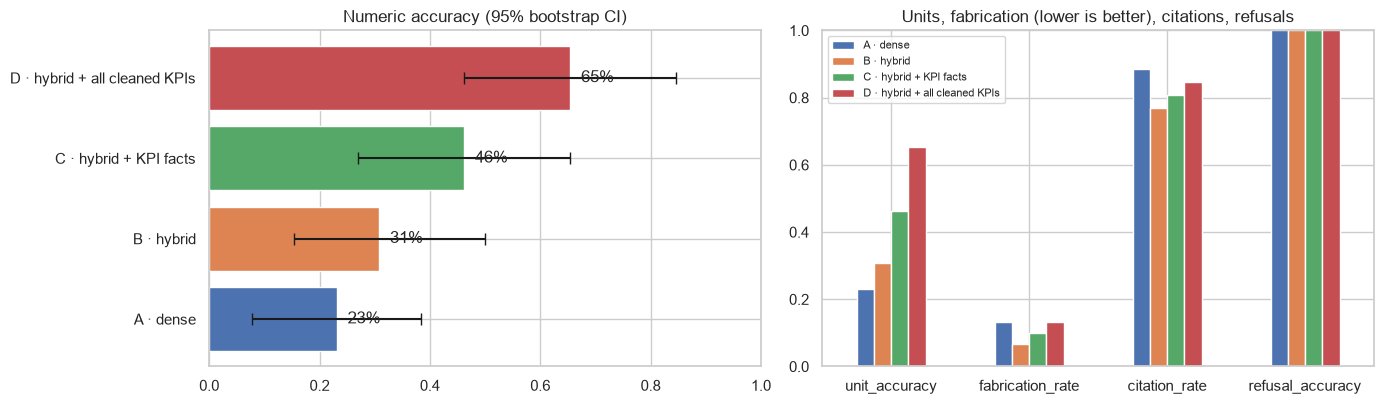

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
s = summary.reset_index()
axes[0].barh(s.config, s.numeric_accuracy, xerr=[s.numeric_accuracy - s.ci_low, s.ci_high - s.numeric_accuracy],
             color=sns.color_palette()[:len(s)], capsize=4)
axes[0].set_xlim(0, 1)
axes[0].set_title("Numeric accuracy (95% bootstrap CI)")
for i, v in enumerate(s.numeric_accuracy):
    axes[0].text(min(v + 0.02, 0.9), i, f"{v:.0%}", va="center")
m = summary[["unit_accuracy", "fabrication_rate", "citation_rate", "refusal_accuracy"]].T
m.plot.bar(ax=axes[1], rot=0, color=sns.color_palette()[:len(s)])
axes[1].set_ylim(0, 1)
axes[1].set_title("Units, fabrication (lower is better), citations, refusals")
axes[1].legend(fontsize=8)
save("config_comparison")

## 3. Is the difference significant? (McNemar's test)

All configurations answer the *same* questions, so the comparison is **paired**. McNemar's test uses only
the discordant questions, i.e. those that one configuration gets right and the other gets wrong. Under H₀
(no difference) these split 50/50, and we use the exact binomial version because the counts are small.

In [6]:
wide = answerable.pivot(index="qid", columns="config", values="numeric_correct").astype(bool)


def mcnemar(a, b):
    b_only = int((~wide[a] & wide[b]).sum())
    a_only = int((wide[a] & ~wide[b]).sum())
    n = a_only + b_only
    p = binomtest(b_only, n, 0.5).pvalue if n else 1.0
    return {"comparison": f"{LABEL[a]} → {LABEL[b]}", "fixed": b_only, "broken": a_only, "p_value": p}


tests = pd.DataFrame([mcnemar("A_dense", "B_hybrid"), mcnemar("B_hybrid", "C_hybrid_facts"),
                      mcnemar("C_hybrid_facts", "D_hybrid_all_kpis"), mcnemar("B_hybrid", "D_hybrid_all_kpis"),
                      mcnemar("A_dense", "D_hybrid_all_kpis")])
tests.round(4)

,comparison,fixed,broken,p_value
0,A · dense → B · hybrid,3,1,0.6250
1,B · hybrid → C · hybrid + KPI facts,5,1,0.2188
2,C · hybrid + KPI facts → D · hybrid + all cleaned KPIs,5,0,0.0625
3,B · hybrid → D · hybrid + all cleaned KPIs,10,1,0.0117
4,A · dense → D · hybrid + all cleaned KPIs,11,0,0.0010


## 4. Per-question view

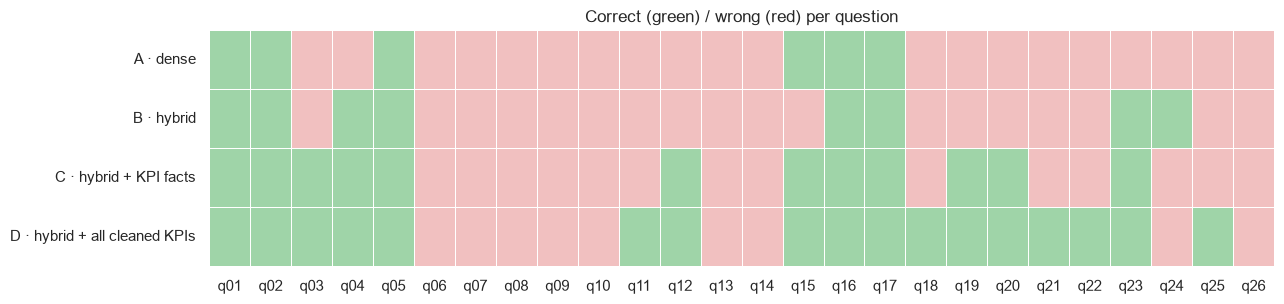

,A · dense,B · hybrid,C · hybrid + KPI facts,D · hybrid + all cleaned KPIs
filing,,,,
adani25,0.0,0.0,0.0,0.0
adani26,0.0,0.0,0.25,0.5
adarsh26,0.6,0.8,1.0,1.0
airtel26,0.0,0.5,0.25,0.5
hal25,0.0,0.0,0.333333,1.0
hal26,0.6,0.4,0.8,1.0


In [7]:
fig, ax = plt.subplots(figsize=(13, 3.2))
grid = wide.T.astype(int).loc[list(CONFIGS)]
grid.index = [LABEL[c] for c in grid.index]
sns.heatmap(grid, cmap=["#f1c0c0", "#9fd4a8"], cbar=False, linewidths=.5, ax=ax)
ax.set_title("Correct (green) / wrong (red) per question")
ax.set_xlabel("")
save("per_question")

by_filing = answerable.groupby(["filing", "config"]).numeric_correct.mean().unstack()[list(CONFIGS)]
by_filing.columns = [LABEL[c] for c in by_filing.columns]
by_filing.round(2)

## 5. Error analysis

In [8]:
best_cfg = summary.numeric_accuracy.idxmax()
best_key = {v: k for k, v in LABEL.items()}[best_cfg]
errs = answerable[(answerable.config == best_key) & ~answerable.numeric_correct].merge(
    qs[["question", "value", "evidence"]], left_on="qid", right_index=True)
print(f"{len(errs)} wrong answers for {best_cfg}:")
errs[["qid", "question", "value", "answer"]].assign(answer=lambda d: d.answer.str.slice(0, 220))

26 wrong answers for D · hybrid + all cleaned KPIs:


,qid,question,value,answer
90,q01,What was the total income for FY 2025-26?,1207.26,"According to Source [4], the Total Income for FY 2025-26 was **₹1,207.26 lakh**."
91,q02,What was the revenue from operations in FY 2025-26?,1203.73,"According to Source [4], the Revenue From Operations for FY 2025-26 was **₹1,203.73 lakh**."
92,q03,What was the profit or loss after tax for FY 2025-26?,-2.38,"According to Source [2], the Loss for the year (FY 2025-26) stands at Rs. (2.38) Lakhs compared to the previous year..."
93,q04,What was the basic earnings per share for FY 2025-26?,-0.02,"According to Source [6], the Basic Earnings Per Share (EPS) for FY 2025-26 was **₹(0.02)**."
94,q05,Did the Board recommend a dividend for FY 2025-26?,NaN,"According to Source [2] and Source [4], the Board has not recommended any dividend for FY 2025-26. Specifically, Sou..."
95,q06,What was the consolidated total income for FY 2024-25?,100365.08,"According to Source [3], the Consolidated FY 2024-25 Revenue for Adani Enterprises Ltd. was **₹2,71,664 crore**."
96,q07,What was the consolidated revenue from operations in FY 2024-25?,97894.75,"According to Source [3], the Consolidated FY 2024-25 Revenue for Adani Enterprises Ltd. was **₹2,71,664 crore**."
97,q08,By what percentage did consolidated revenue from operations change from FY 2023-24 to FY 2024-25?,1.53,"To determine the percentage change in consolidated revenue from operations from FY 2023-24 to FY 2024-25, we need to..."
98,q09,What was the consolidated profit for the year FY 2024-25?,8004.99,"According to Source [2], the consolidated profit before tax (PBT) for the full fiscal year 2024-25 was ₹6,533 crore."
99,q10,What was the standalone revenue from operations in FY 2024-25?,26708.97,"To find the standalone revenue from operations for FY 2024-25, we need to look at the consolidated revenue figures a..."


In [9]:
fab = scored[scored.fabricated][["config", "qid", "unsupported"]]
print("Answers containing figures absent from every source:")
fab.assign(config=fab.config.map(LABEL)).head(15)

Answers containing figures absent from every source:


,config,qid,unsupported
2,A · dense,q03,[(30.71) Lakhs]
5,A · dense,q06,"[₹1,207.26 crore]"
18,A · dense,q19,"[100, 100, 497, 100, 2.09, 2.09%]"
20,A · dense,q21,[87]
37,B · hybrid,q08,"[₹2,65,051 crore, 2,65,051, 2,65,051, 6,613, 2,65,051, 0.0248, 2.48, 2.48%]"
51,B · hybrid,q22,"[₹3,81,70,76,000]"
67,C · hybrid + KPI facts,q08,"[6,710]"
78,C · hybrid + KPI facts,q19,"[3,247.09, 0.0967, 9.67, 9.67%]"
80,C · hybrid + KPI facts,q21,"[₹8,317.28 crore]"
97,D · hybrid + all cleaned KPIs,q08,"[₹2,55,053 crore, 2,55,053, 2,55,053, 16,611, 2,55,053, 6.53, 6.53%]"


**Failure modes of the selected configuration.** These were read from the wrong answers above; question IDs
refer to `rag_gold.json`.

| Failure mode | Examples | Fix that would address it |
|---|---|---|
| **Retrieval misses the statement page.** The model answers from narrative text, such as a group-level figure in the Chairman's letter, or refuses. | q06, q07, q10, q13 | Use the PageClassifier labels to boost *statement* pages for numeric questions |
| **Wrong row of the KPI table**, e.g. *Current Assets* given for "total assets" | q22, q25 | Put the headline KPIs first and give exact-name matching priority; fine-tune (FinSumm) |
| **Wrong value in the KPI table** (an extraction error) | q26 (Airtel EPS) | KPI-NER, the next model on the roadmap |
| **Definition or scope mix-up**: profit *attributable to owners* vs total profit, PBT vs profit | q09, q24 | Grounded-QA fine-tuning; scope tags (standalone / consolidated) in the KPI table |

All configurations refused all four unanswerable questions, and C cuts fabricated figures compared with
the dense baseline. The remaining errors are mostly *wrong but sourced* numbers, not invented ones.

**Known source of error for C.** The KPI table can itself be wrong. For Bharti Airtel, the extractor
stored PAT ₹40,050 Cr and EPS ₹4.80, while the consolidated P&L (page 216) reports profit ₹33,823 Cr and
EPS ₹45.96. When configuration C trusts such a row, the error propagates into the answer. The facts are
only as good as KPI extraction, which is why the KPI-NER model is the next item on the roadmap.

In [10]:
airtel = scored[(scored.filing == "airtel26") & (scored.kind != "unanswerable")]
airtel.pivot(index="qid", columns="config", values="numeric_correct").rename(columns=LABEL)

config,A · dense,B · hybrid,C · hybrid + KPI facts,D · hybrid + all cleaned KPIs
qid,,,,
q23,False,True,True,True
q24,False,True,False,False
q25,False,False,False,True
q26,False,False,False,False


## 6. Decision

In [11]:
order = summary.sort_values(["numeric_accuracy", "fabrication_rate"], ascending=[False, True])
chosen = order.index[0]
bc = tests.set_index("comparison").loc[f"{LABEL['B_hybrid']} → {chosen}"] if chosen != LABEL["B_hybrid"] else None
decision = {
    "selected": chosen,
    "reason": (f"{chosen} has the highest numeric accuracy ({summary.loc[chosen, 'numeric_accuracy']:.0%}, "
               f"95% CI {summary.loc[chosen, 'ci_low']:.0%}–{summary.loc[chosen, 'ci_high']:.0%}) and a fabrication rate "
               f"of {summary.loc[chosen, 'fabrication_rate']:.0%}."
               + (f" Versus plain hybrid retrieval it fixed {int(bc.fixed)} and broke {int(bc.broken)} questions "
                  f"(McNemar exact p = {bc.p_value:.3f})." if bc is not None else "")),
    "deployed_setting": {LABEL["D_hybrid_all_kpis"]: "qa_use_kpi_facts=True, all cleaned rows (default)",
                         LABEL["C_hybrid_facts"]: "qa_use_kpi_facts=True, verified_only=True"}.get(chosen, "qa_use_kpi_facts=False"),
}
print(json.dumps(decision, indent=1, ensure_ascii=False))

{
 "selected": "D · hybrid + all cleaned KPIs",
 "reason": "D · hybrid + all cleaned KPIs has the highest numeric accuracy (65%, 95% CI 46%–85%) and a fabrication rate of 13%. Versus plain hybrid retrieval it fixed 10 and broke 1 questions (McNemar exact p = 0.012).",
 "deployed_setting": "qa_use_kpi_facts=True, all cleaned rows (default)"
}


The production setting `qa_use_kpi_facts` (backend config) follows this decision. With 26 answerable
questions the confidence intervals are wide, so the McNemar p-value, not the raw percentage gap, says
whether a difference is real. Extending the gold set is the cheapest way to tighten it.

In [12]:
metrics_path = REPORTS_DIR / "metrics.json"
metrics = json.loads(metrics_path.read_text(encoding="utf-8")) if metrics_path.exists() else {}
metrics["rag"] = {
    "gold_questions": int(len(qs)), "answerable": int((qs.kind != "unanswerable").sum()),
    "llm": "qwen2.5:3b (Ollama, local)",
    "summary": summary.reset_index().round(4).to_dict("records"),
    "mcnemar": tests.round(4).to_dict("records"),
    "decision": decision,
}
metrics["comparisons"] = [c for c in metrics.get("comparisons", []) if not c["title"].startswith("Q&A")] + [
    {"title": "Q&A configurations · numeric accuracy (gold set)", "metric": "accuracy",
     "results": [{"model": i, "score": round(float(r.numeric_accuracy), 4)} for i, r in summary.iterrows()]},
    {"title": "Q&A configurations · fabricated-figure rate (lower is better)", "metric": "rate",
     "results": [{"model": i, "score": round(float(r.fabrication_rate), 4)} for i, r in summary.iterrows()]},
]
metrics_path.write_text(json.dumps(metrics, indent=1, ensure_ascii=False, default=float), encoding="utf-8")
print("updated metrics.json → rag")

updated metrics.json → rag
